# Baseline Embedding (Member B)

Stable Diffusion 1.5 does not read text directly. Each caption is tokenized, padded to 77 tokens and passed
through the **CLIP ViT-L/14 text encoder**. The encoder's last hidden state, a **77 x 768** tensor, is the
conditioning the UNet attends to through cross-attention at every denoising step.

This notebook:
1. checks the environment (PyTorch, Diffusers, Transformers, device),
2. loads the CLIP text encoder from the SD 1.5 checkpoint,
3. tokenizes and embeds all 2,000 captions in `data/subset.csv`,
4. verifies shape and numerical sanity, and
5. checks that similar captions get similar embeddings.

## 1. Environment

In [1]:
import os, sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import torch
import transformers, diffusers
import matplotlib.pyplot as plt

import embed

transformers.utils.logging.disable_progress_bar()

print(f"python       {sys.version.split()[0]}")
print(f"torch        {torch.__version__}")
print(f"transformers {transformers.__version__}")
print(f"diffusers    {diffusers.__version__}")
device = embed.get_device()
print(f"device       {device}")

python       3.10.22
torch        2.14.1
transformers 5.20.2
diffusers    0.41.0
device       mps


## 2. Load the caption subset

In [2]:
df = pd.read_csv(ROOT / "data" / "subset.csv")
print(f"{len(df)} captions, {df['category'].nunique()} categories, {df['supercategory'].nunique()} supercategories")
df[["image_id", "caption", "category", "supercategory"]].head()

2000 captions, 80 categories, 12 supercategories


,image_id,caption,category,supercategory
0,139,a woman standing in a kitchen by a window,microwave,appliance
1,632,"bedroom scene with a bookcase, blue comforter ...",chair,furniture
2,872,two baseball players are playing baseball on a...,baseball glove,sports
3,1268,the woman is taking a photo of the white goose...,bird,animal
4,1490,black and white of a person wearing a wetsuit ...,surfboard,sports


## 3. Load the CLIP ViT-L/14 text encoder

We load the tokenizer and text encoder from the `stable-diffusion-v1-5` checkpoint itself, so the embeddings
are identical to what the generation pipeline will compute internally.

In [3]:
tokenizer, encoder = embed.load_text_encoder(device)
n_params = sum(p.numel() for p in encoder.parameters())
cfg = encoder.config
print(f"model:        {embed.MODEL_ID} (text_encoder)")
print(f"parameters:   {n_params / 1e6:.1f}M")
print(f"layers:       {cfg.num_hidden_layers}, hidden size {cfg.hidden_size}, heads {cfg.num_attention_heads}")
print(f"max length:   {tokenizer.model_max_length} tokens, vocab {tokenizer.vocab_size}")

model:        stable-diffusion-v1-5/stable-diffusion-v1-5 (text_encoder)
parameters:   123.1M
layers:       12, hidden size 768, heads 12
max length:   77 tokens, vocab 49408


## 4. Tokenization

Each caption becomes `<start> ... <end>` followed by padding up to 77 tokens. Captions longer than 77 tokens
would be truncated, so we check how long ours are.

In [4]:
example = df["caption"].iloc[0]
ids = embed.tokenize(tokenizer, [example]).input_ids[0]
n_real = len(tokenizer(example).input_ids)
print(f"caption: {example!r}")
print(f"tokens:  {tokenizer.convert_ids_to_tokens(ids[:n_real].tolist())}")
print(f"ids:     {ids[:n_real].tolist()} + {77 - n_real} padding tokens")

caption: 'a woman standing in a kitchen by a window'
tokens:  ['<|startoftext|>', 'a</w>', 'woman</w>', 'standing</w>', 'in</w>', 'a</w>', 'kitchen</w>', 'by</w>', 'a</w>', 'window</w>', '<|endoftext|>']
ids:     [49406, 320, 2308, 2862, 530, 320, 4485, 638, 320, 4879, 49407] + 66 padding tokens


token length: min 9, mean 12.9, max 32
captions truncated at 77 tokens: 0


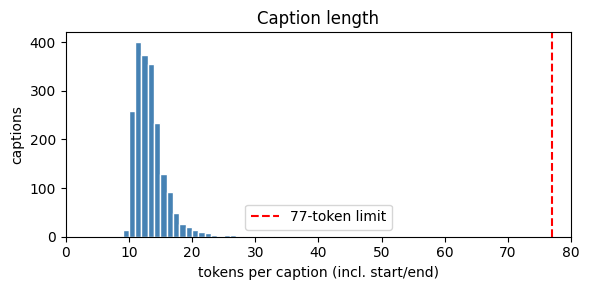

In [5]:
lengths = np.array([len(tokenizer(c).input_ids) for c in df["caption"]])
print(f"token length: min {lengths.min()}, mean {lengths.mean():.1f}, max {lengths.max()}")
print(f"captions truncated at 77 tokens: {(lengths > embed.MAX_LEN).sum()}")

plt.figure(figsize=(6, 3))
plt.hist(lengths, bins=range(lengths.min(), lengths.max() + 2), color="steelblue", edgecolor="white")
plt.axvline(embed.MAX_LEN, color="red", ls="--", label="77-token limit")
plt.xlim(0, 80); plt.xlabel("tokens per caption (incl. start/end)"); plt.ylabel("captions")
plt.title("Caption length"); plt.legend(); plt.tight_layout(); plt.show()

## 5. Embed all captions

In [6]:
import time
t0 = time.time()
hidden, pooled = embed.encode(df["caption"], tokenizer, encoder, batch_size=64)
print(f"encoded {len(df)} captions in {time.time() - t0:.1f}s on {device}")
print(f"hidden (SD conditioning): {tuple(hidden.shape)}  {hidden.dtype}")
print(f"pooled (one per caption): {tuple(pooled.shape)}  {pooled.dtype}")

encoded 2000 captions in 13.3s on mps
hidden (SD conditioning): (2000, 77, 768)  torch.float32
pooled (one per caption): (2000, 768)  torch.float32


In [7]:
assert hidden.shape == (len(df), embed.MAX_LEN, embed.EMBED_DIM)
assert pooled.shape == (len(df), embed.EMBED_DIM)
assert not torch.isnan(hidden).any() and not torch.isinf(hidden).any()
assert not torch.isnan(pooled).any()
print("shape and NaN/Inf checks passed")
print(f"hidden stats: mean {hidden.mean():.3f}, std {hidden.std():.3f}, min {hidden.min():.2f}, max {hidden.max():.2f}")

shape and NaN/Inf checks passed
hidden stats: mean -0.109, std 1.015, min -28.09, max 33.06


In [8]:
out_path = ROOT / "data" / "embeddings.pt"
embed.save_embeddings(out_path, df, hidden, pooled)
print(f"saved to {out_path.relative_to(ROOT)} ({out_path.stat().st_size / 1e6:.0f} MB, fp16)")

saved to data/embeddings.pt (240 MB, fp16)


## 6. Do similar captions get similar embeddings?

We compare captions with the cosine similarity of their pooled embedding (the end-of-text token, which
summarizes the whole caption). For each anchor we write a paraphrase and an unrelated caption: the
paraphrase should score clearly higher.

In [9]:
triples = [
    ("a dog running on the beach", "a puppy playing in the sand by the ocean", "a plate of pasta with tomato sauce"),
    ("a man riding a surfboard on a wave", "a surfer catching a big wave in the ocean", "a red stop sign on a street corner"),
    ("a cat sleeping on a couch", "a kitten napping on the sofa", "an airplane flying over the city"),
    ("a bowl of fresh fruit on a table", "apples and bananas in a bowl", "a baseball player swinging a bat"),
    ("a train pulling into the station", "a passenger train stopped at a platform", "a woman holding an umbrella in the rain"),
]
rows = []
for anchor, similar, unrelated in triples:
    _, p = embed.encode([anchor, similar, unrelated], tokenizer, encoder)
    s = embed.cosine_matrix(p)
    rows.append({"anchor": anchor, "similar": similar, "sim(similar)": round(s[0, 1].item(), 3),
                 "unrelated": unrelated, "sim(unrelated)": round(s[0, 2].item(), 3)})
pairs = pd.DataFrame(rows)
assert (pairs["sim(similar)"] > pairs["sim(unrelated)"]).all()
print("similar > unrelated for every pair")
pairs

similar > unrelated for every pair


,anchor,similar,sim(similar),unrelated,sim(unrelated)
0,a dog running on the beach,a puppy playing in the sand by the ocean,0.785,a plate of pasta with tomato sauce,0.223
1,a man riding a surfboard on a wave,a surfer catching a big wave in the ocean,0.832,a red stop sign on a street corner,0.295
2,a cat sleeping on a couch,a kitten napping on the sofa,0.861,an airplane flying over the city,0.338
3,a bowl of fresh fruit on a table,apples and bananas in a bowl,0.672,a baseball player swinging a bat,0.264
4,a train pulling into the station,a passenger train stopped at a platform,0.834,a woman holding an umbrella in the rain,0.275


### Dataset-level check

Across the 2,000 captions, two captions labeled with the same COCO category should on average be more similar
than two captions from different categories.

In [10]:
S = embed.cosine_matrix(pooled)
cat = df["category"].values
same = torch.tensor(cat[:, None] == cat[None, :])
off_diag = ~torch.eye(len(df), dtype=torch.bool)
within = S[same & off_diag].mean().item()
across = S[~same].mean().item()
print(f"mean cosine, same category:      {within:.3f}")
print(f"mean cosine, different category: {across:.3f}")
assert within > across

mean cosine, same category:      0.401
mean cosine, different category: 0.242


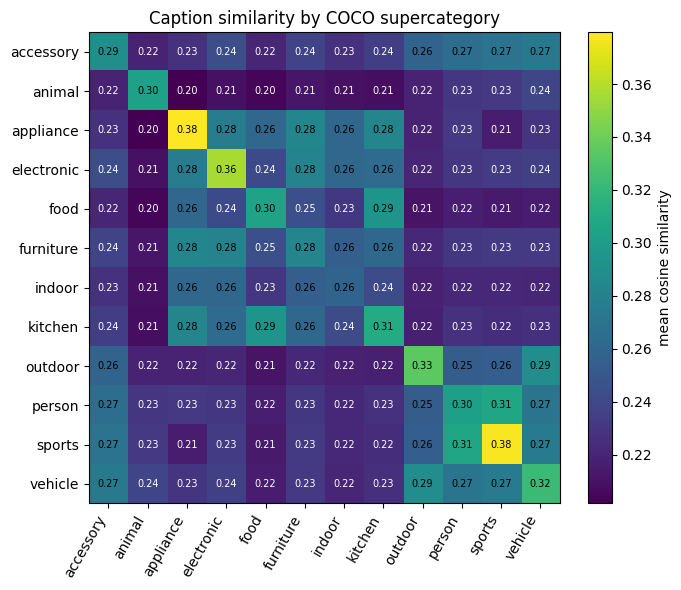

In [11]:
supers = sorted(df["supercategory"].unique())
idx = {s: np.where(df["supercategory"].values == s)[0] for s in supers}
M = np.array([[S[np.ix_(idx[a], idx[b])].mean().item() for b in supers] for a in supers])

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(M, cmap="viridis")
ax.set_xticks(range(len(supers)), supers, rotation=60, ha="right")
ax.set_yticks(range(len(supers)), supers)
for i in range(len(supers)):
    for j in range(len(supers)):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="black" if M[i, j] > M.mean() else "white")
fig.colorbar(im, fraction=0.046, label="mean cosine similarity")
ax.set_title("Caption similarity by COCO supercategory")
plt.tight_layout(); plt.show()

The diagonal is brightest: captions about the same kind of scene sit closer together in CLIP space.

### Nearest neighbors within the subset

In [12]:
for i in [0, 3, 500, 1200]:
    sims = S[i].clone(); sims[i] = -1
    top = sims.topk(3)
    print(f"[{df['category'][i]}] {df['caption'][i]}")
    for score, j in zip(top.values, top.indices):
        print(f"    {score:.3f}  [{df['category'][j.item()]}] {df['caption'][j.item()]}")
    print()

[microwave] a woman standing in a kitchen by a window
    0.814  [spoon] a woman is standing in a professional kitchen
    0.696  [toothbrush] a beautiful woman cooking food in a kitchen
    0.670  [spoon] a woman standing at a kitchen counter with a child and a dog is behind her

[bird] the woman is taking a photo of the white goose next to the river
    0.558  [book] a man is taking a picture of his food
    0.544  [cell phone] a woman holding a camera is taking a picture
    0.508  [vase] a woman taking a photo of her food with a cell phone

[couch] several pieces of wood lined up near a lot with several axes around
    0.494  [surfboard] several surfboards standing in a row on the beach
    0.488  [traffic light] a couple of signs are on a wood pole
    0.479  [motorcycle] a row of foreign motorcycles is lined up in front of a wooden fence

[scissors] an oversized pair of scissors are held by a hand
    0.682  [scissors] a persons hand with a pair of scissors
    0.597  [scissors] 

## Summary

- Environment: PyTorch, Diffusers and Transformers load correctly and the encoder runs on the available accelerator.
- The SD 1.5 CLIP ViT-L/14 text encoder turns each of the 2,000 captions into a **77 x 768** embedding with no NaNs; no caption exceeds the 77-token limit.
- Embeddings are semantically meaningful: paraphrases score far higher than unrelated captions, and same-category captions are more similar than cross-category ones.
- Embeddings are saved to `data/embeddings.pt` (`hidden`, `pooled`, `image_id`, `caption`) for the tests and generation steps. Regenerate with `python src/embed.py`.